In [23]:
import pandas as pd
import numpy as np
from pathlib import Path
import parts

DATA = Path('../data')
MARKET_SIZE = 'hh'
PRICE_VAR, LOG_PRICE = 'eurpr', True
SEGMENT = 'cla'

cars = pd.read_csv(DATA / 'cars.csv')


# Calculate shares on the full dataset, before selecting a market
cars['market_size'], cars['s'], cars['s0'] = parts.market_size_function(data=cars, type=MARKET_SIZE)
cars['segment_share'] = (cars.groupby(['ma', 'ye', SEGMENT])['s'].transform('sum'))

lbl_vars = pd.read_csv(DATA / 'labels_variables.csv', index_col=0)['label']
lbl_vals = pd.read_stata(DATA / 'cars.dta', iterator=True).value_labels()



# load in parameters from estimation code
params = pd.read_csv(DATA / 'demand_model_parameters.csv', index_col=0)

alpha_simple = params.loc['alpha', 'Simple logit']
alpha_extended = params.loc['alpha', 'Extended logit']
rho_extended = params.loc['log_within_segment_share', 'Extended logit']



In [24]:
MARKET_YE = 99

def elasticity(pairs, alpha, rho):
    r = 1 / (1 - rho)
    own = pairs['co_j'] == pairs['co_k']
    same_segment = pairs[f'{SEGMENT}_j'] == pairs[f'{SEGMENT}_k']
    dp = 1 if LOG_PRICE else pairs[PRICE_VAR]

    return -alpha * dp * (r * own - (r - 1) * same_segment * pairs['s'] / pairs['segment_share']  - pairs['s'])

results_list = []

market_codes = (cars.loc[cars['ye'].eq(MARKET_YE), 'ma'].drop_duplicates().tolist())

for MARKET_MA in market_codes:

    market = (cars.loc[cars['ma'].eq(MARKET_MA) & cars['ye'].eq(MARKET_YE)].sort_values('brand').reset_index(drop=True))

    if market.empty:
        continue

    # Every product pair in this market; s and segment_share refer to product k
    cols = ['ma', 'ye', 'co', SEGMENT]
    pairs = market[cols].merge(market[cols + ['s', 'segment_share', PRICE_VAR]], on=['ma', 'ye'],suffixes=('_j', '_k'))

    pairs['simple'] = elasticity(pairs, alpha_simple, rho=0)
    pairs['extended'] = elasticity(pairs, alpha_extended, rho_extended)

    # Rows: share responding; columns: price changing
    product_order = market['co'].tolist()

    E_simple = (pairs.pivot(index='co_j', columns='co_k', values='simple').reindex(index=product_order, columns=product_order))
    E_extended = (pairs.pivot(index='co_j', columns='co_k', values='extended').reindex(index=product_order, columns=product_order))

    # Align shares and prices with the elasticity matrices
    market_ordered = market.set_index('co').loc[product_order]
    shares = market_ordered['s'].to_numpy()
    prices = market_ordered[PRICE_VAR].to_numpy()

    def share_jacobian(E):
        values = E.to_numpy().T * (shares[None, :] / prices[:, None])
        return values

    J_simple = share_jacobian(E_simple)
    J_extended = share_jacobian(E_extended)

    # Ownership matrices before and after the merger
    j = len(market)
    H = np.zeros((j, j))
    H_merge = np.zeros((j, j))

    for i in range(j):
        for k in range(j):
            if market.loc[i, 'brand'] == market.loc[k, 'brand']:
                H[i, k] = 1

            if (
                market.loc[i, 'brand'] == market.loc[k, 'brand']
                or (market.loc[i, 'brand'] == 'VW'
                    and market.loc[k, 'brand'] == 'fiat')
                or (market.loc[i, 'brand'] == 'fiat'
                    and market.loc[k, 'brand'] == 'VW')
            ):
                H_merge[i, k] = 1

    # Marginal costs, calculated separately for each demand model
    markup_simple = np.linalg.solve(H * J_simple, -shares)
    mc_simple = prices - markup_simple

    markup_extended = np.linalg.solve(H * J_extended, -shares)
    mc_extended = prices - markup_extended

    # Recover mean utility from observed shares
    nests = market_ordered[SEGMENT].to_numpy()
    nest_id = nests.reshape(1, -1)
    nest_data = {'nest_id': nest_id}

    s0_obs = float(market_ordered['s0'].iloc[0])
    S_obs = np.r_[s0_obs, shares].reshape(1, -1)

    delta_simple = parts.invert_demand(S_obs, rho=0, nest_id=nest_id)[0]
    delta_extended = parts.invert_demand(S_obs, rho=rho_extended, nest_id=nest_id)[0]

    # Solve pre- and post-merger prices
    p_simple_pre = parts.solve_nash(H, mc_simple, prices, delta_simple, nest_data, alpha_simple, rho=0)
    p_simple_post = parts.solve_nash(H_merge, mc_simple, prices, delta_simple, nest_data, alpha_simple, rho=0)

    p_extended_pre = parts.solve_nash(H, mc_extended, prices, delta_extended, nest_data, alpha_extended, rho=rho_extended)
    p_extended_post = parts.solve_nash(H_merge, mc_extended, prices, delta_extended, nest_data, alpha_extended, rho=rho_extended)

    # Keep product identifiers and prices for this market
    result_market = market_ordered.reset_index()[['ma', 'ye', 'co', 'type', 'brand', 's']].rename(columns={'s': 'share_pre'})

    result_market['price_observed'] = prices

    result_market['simple_pre'] = p_simple_pre
    result_market['simple_post'] = p_simple_post
    result_market['simple_change'] = p_simple_post - p_simple_pre
    result_market['simple_change_pct'] = (100 * (p_simple_post / p_simple_pre - 1)
    )

    result_market['extended_pre'] = p_extended_pre
    result_market['extended_post'] = p_extended_post
    result_market['extended_change'] = p_extended_post - p_extended_pre
    result_market['extended_change_pct'] = (100 * (p_extended_post / p_extended_pre - 1))

    # Check pre-merger prices reproduce observed prices
    print(
        f"ma={MARKET_MA}: max pre-merger price difference — "
        f"simple {np.max(np.abs(p_simple_pre - prices)):.6g}; "
        f"extended {np.max(np.abs(p_extended_pre - prices)):.6g}"
    )

    results_list.append(result_market)


# Combine results from all ma markets
results = pd.concat(results_list, ignore_index=True)

# Save the combined results
from pathlib import Path

RES = Path('../res/demand models')
RES.mkdir(parents=True, exist_ok=True)

results.to_csv(RES / f'merger_prices_ye_{MARKET_YE}.csv', index=False)

ma=1: max pre-merger price difference — simple 0; extended 1.81899e-12
ma=2: max pre-merger price difference — simple 9.09495e-13; extended 0
ma=3: max pre-merger price difference — simple 9.09495e-13; extended 1.81899e-12
ma=4: max pre-merger price difference — simple 1.81899e-12; extended 1.81899e-12
ma=5: max pre-merger price difference — simple 3.63798e-12; extended 0


In [ ]:
model_specs = [
    ('Simple logit', 'simple_change', 'simple_change_pct'),
    ('Extended nested logit', 'extended_change', 'extended_change_pct'),
]

# Summaries for each ma, plus one pooled summary across all ma
groups = [(ma, g) for ma, g in results.groupby('ma', sort=True)]
groups.append(('All ma', results))

summary_rows = []

for ma, g in groups:
    brand = g['brand'].astype(str).str.casefold()

    for model, change_col, pct_col in model_specs:
        # Product with the largest price increase
        max_index = g[change_col].idxmax()
        max_product = g.loc[max_index]

        summary_rows.append({
            'market': ma,
            'model': model,
            'average_pct_change_all_products': g[pct_col].mean(),
            'largest_price_increase_euros': max_product[change_col],
            'pct_change_for_largest_increase': max_product[pct_col],
            'product_with_largest_increase': max_product['type'],
            'average_pct_change_fiat': g.loc[brand.eq('fiat'), pct_col].mean(),
            'average_pct_change_vw': g.loc[brand.eq('vw'), pct_col].mean(),
        })


merger_overview = pd.DataFrame(summary_rows).round(2)
ma_labels = cars.drop_duplicates('ma').set_index('ma')['market']

merger_overview['market'] = merger_overview['market'].map(ma_labels).fillna(merger_overview['market'])


merger_overview

,market,model,average_pct_change_all_products,largest_price_increase_euros,pct_change_for_largest_increase,product_with_largest_increase,average_pct_change_fiat,average_pct_change_vw
0,Belgium,Simple logit,0.05,114.88,1.93,fiat punto,1.93,0.06
1,Belgium,Extended nested logit,0.02,42.63,0.72,fiat punto,0.72,0.03
2,France,Simple logit,0.07,47.69,0.60,fiat palio,0.62,0.21
3,France,Extended nested logit,0.04,37.35,0.39,fiat bravo/brava,0.31,0.12
4,Germany,Simple logit,0.05,154.27,1.42,fiat punto,1.42,0.10
5,Germany,Extended nested logit,0.03,65.99,0.61,fiat punto,0.61,0.09
6,Italy,Simple logit,0.27,137.14,0.96,volkswagen passat,0.95,1.46
7,Italy,Extended nested logit,0.14,103.77,0.73,volkswagen passat,0.46,0.78
8,UK,Simple logit,0.04,64.76,0.50,fiat bravo/brava,0.60,0.15
9,UK,Extended nested logit,0.02,40.80,0.32,fiat bravo/brava,0.29,0.08


In [2]:
# Select the chosen market
# Market to analyze
MARKET_MA = 3
MARKET_YE = 99

market = (cars.loc[cars['ma'].eq(MARKET_MA) & cars['ye'].eq(MARKET_YE)].sort_values('brand').reset_index(drop=True))

if market.empty:
    raise ValueError(f"No products found for ma={MARKET_MA}, ye={MARKET_YE}")


# Every product pair in the selected market.
# s and segment_share refer to product k.
cols = ['ma', 'ye', 'co', SEGMENT]

pairs = market[cols].merge( market[cols + ['s', 'segment_share', PRICE_VAR]], on=['ma', 'ye'], suffixes=('_j', '_k')
)

def elasticity(pairs, alpha, rho):
    r = 1 / (1 - rho)
    own = pairs['co_j'] == pairs['co_k']
    same_segment = pairs[f'{SEGMENT}_j'] == pairs[f'{SEGMENT}_k']
    dp = 1 if LOG_PRICE else pairs[PRICE_VAR]
    return -alpha * dp * (r * own - (r - 1) * same_segment * pairs['s'] / pairs['segment_share'] - pairs['s'])

pairs['simple'] = elasticity(pairs, alpha_simple, rho=0)
pairs['extended'] = elasticity(pairs, alpha_extended, rho_extended)

# Rows = product whose share responds (j)
# Columns = product whose price changes (k)
product_order = market['co'].tolist()

E_simple = (
    pairs.pivot(index='co_j', columns='co_k', values='simple')
    .reindex(index=product_order, columns=product_order)
)

E_extended = (
    pairs.pivot(index='co_j', columns='co_k', values='extended')
    .reindex(index=product_order, columns=product_order)
)

# Shares and price levels in the same product order as the elasticity matrices
market_ordered = market.set_index('co').loc[product_order]
shares = market_ordered['s'].to_numpy()
prices = market_ordered[PRICE_VAR].to_numpy()

def share_jacobian(E):
    values = E.to_numpy().T * (shares[None, :] / prices[:, None])
    return pd.DataFrame(values, index=pd.Index(product_order, name='price changed'),columns=pd.Index(product_order, name='share responding') )

J_simple = share_jacobian(E_simple)
J_extended = share_jacobian(E_extended)

# make ownership matrix before merger 
j = len(market)

# make a jxj matrix of zeros
H = np.zeros((j, j))
# make a jxj matrix of zeros
H_merge = np.zeros((j, j))


# make the H matrix such that if the j product is owned by the brand x then jeg H_1j-H_jj and H_j1-H_jj are equal to the brand value
for i in range(j):
    for k in range(j):
        if market.loc[i, 'brand'] == market.loc[k, 'brand']:
            H[i, k] = 1


        if (market.loc[i, "brand"] == market.loc[k, "brand"]
            or (market.loc[i, "brand"] == "VW" and market.loc[k, "brand"] == "fiat")
            or (market.loc[i, "brand"] == "fiat"and market.loc[k, "brand"] == "VW")):

            H_merge[i, k] = 1

markup_simple = np.linalg.solve(H * J_simple.to_numpy(), -shares)
mc_simple = prices - markup_simple

markup_extended = np.linalg.solve(H * J_extended.to_numpy(), -shares)
mc_extended = prices - markup_extended

nests = market_ordered[SEGMENT].to_numpy()
nest_id = nests.reshape(1, -1)
nest_data = {'nest_id': nest_id}

s0_obs = float(market_ordered['s0'].iloc[0])
S_obs = np.r_[s0_obs, shares].reshape(1, -1)

delta_simple = parts.invert_demand(S_obs, rho=0, nest_id=nest_id)[0]
delta_extended = parts.invert_demand(
    S_obs, rho=rho_extended, nest_id=nest_id
)[0]

# Simple logit
p_simple_pre = parts.solve_nash(H, mc_simple, prices, delta_simple, nest_data, alpha_simple, rho=0)
p_simple_merger = parts.solve_nash(H_merge, mc_simple, prices, delta_simple, nest_data, alpha_simple, rho=0)

# Extended nested logit
p_extended_pre = parts.solve_nash(H, mc_extended, prices, delta_extended, nest_data, alpha_extended, rho=rho_extended)
p_extended_merger = parts.solve_nash(H_merge, mc_extended, prices, delta_extended, nest_data, alpha_extended, rho=rho_extended)

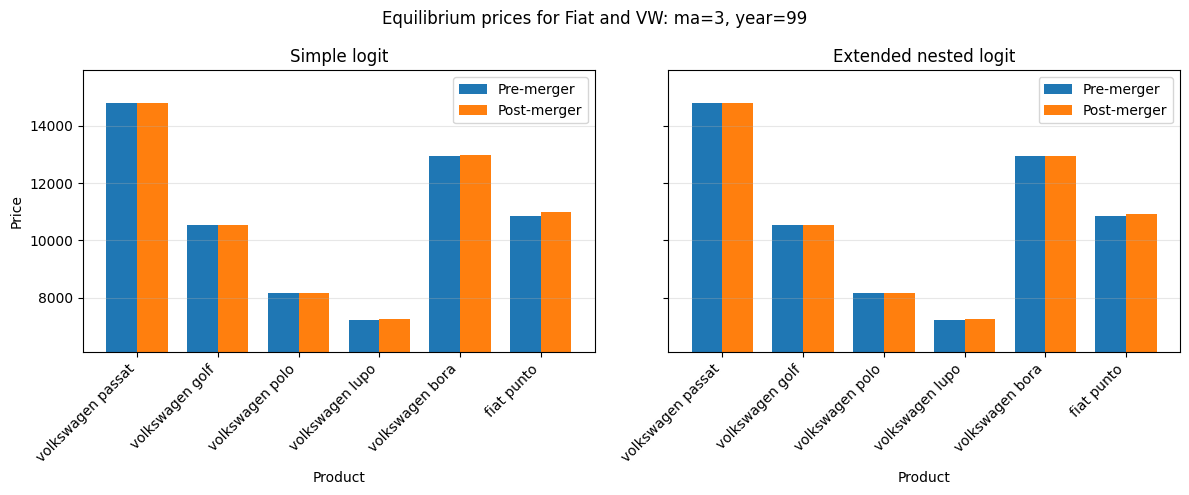

In [3]:
import matplotlib.pyplot as plt
import numpy as np

# Keep only Fiat and VW products
brand_mask = (
    market_ordered['brand'].astype(str).str.casefold().isin(['fiat', 'vw']).to_numpy()
)
products = market_ordered.loc[brand_mask, 'type'].astype(str).to_numpy()
x = np.arange(len(products))
width = 0.38

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

plots = [
    (axes[0], p_simple_pre[brand_mask], p_simple_merger[brand_mask], 'Simple logit'),
    (axes[1], p_extended_pre[brand_mask], p_extended_merger[brand_mask],
     'Extended nested logit'),
]

# Use the same zoomed price range in both panels
all_prices = np.concatenate([pre for _, pre, _, _ in plots] +
                            [post for _, _, post, _ in plots])
pad = max((all_prices.max() - all_prices.min()) * 0.15, 1)
y_min, y_max = all_prices.min() - pad, all_prices.max() + pad

for ax, pre, post, title in plots:
    ax.bar(x - width/2, pre, width, label='Pre-merger')
    ax.bar(x + width/2, post, width, label='Post-merger')
    ax.set_title(title)
    ax.set_xlabel('Product')
    ax.set_xticks(x)
    ax.set_xticklabels(products, rotation=45, ha='right')
    ax.set_ylim(y_min, y_max)
    ax.grid(axis='y', alpha=0.3)
    ax.legend()

axes[0].set_ylabel('Price')
fig.suptitle(f'Equilibrium prices for Fiat and VW: ma={MARKET_MA}, year={MARKET_YE}')
fig.tight_layout()
plt.show()

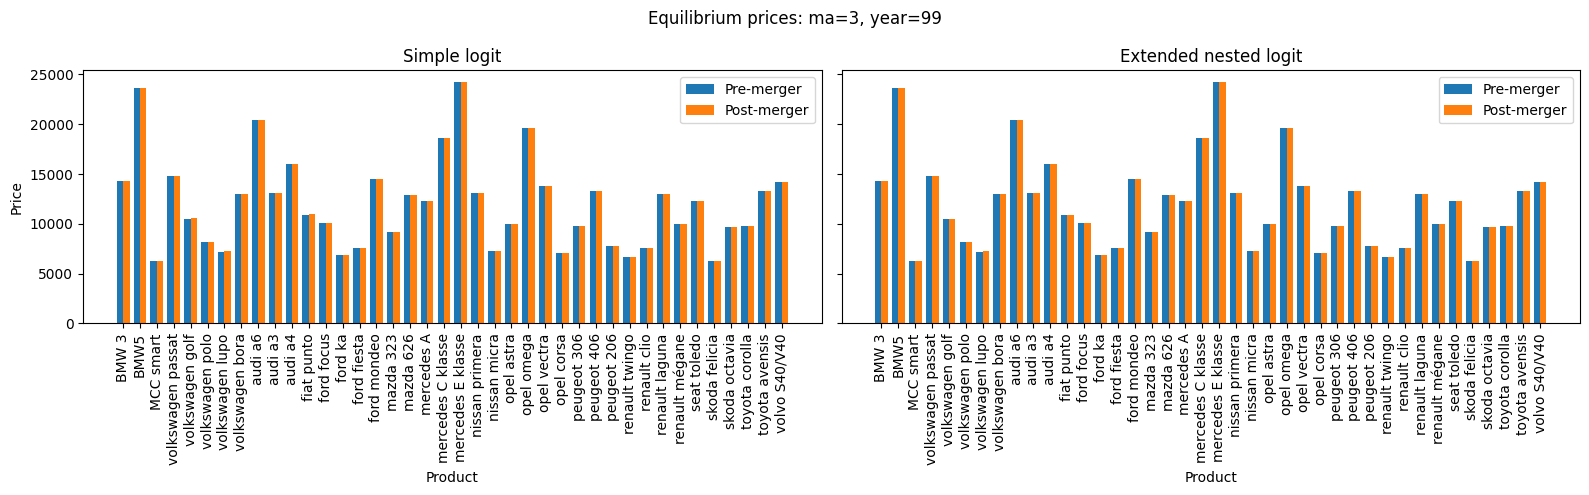

In [4]:
import matplotlib.pyplot as plt
import numpy as np

products = market_ordered['type'].astype(str).to_numpy()
x = np.arange(len(products))
width = 0.38

fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)

for ax, pre, post, title in [
    (axes[0], p_simple_pre, p_simple_merger, 'Simple logit'),
    (axes[1], p_extended_pre, p_extended_merger, 'Extended nested logit')
]:
    ax.bar(x - width/2, pre, width, label='Pre-merger')
    ax.bar(x + width/2, post, width, label='Post-merger')
    ax.set_title(title)
    ax.set_xlabel('Product')
    ax.set_xticks(x)
    ax.set_xticklabels(products, rotation=90)
    ax.legend()

axes[0].set_ylabel('Price')
fig.suptitle(f'Equilibrium prices: ma={MARKET_MA}, year={MARKET_YE}')
fig.tight_layout()
plt.show()

In [5]:
price_changes = pd.DataFrame({
    'product': market_ordered['type'].to_numpy(),
    'brand': market_ordered['brand'].to_numpy(),
    'simple_pre': p_simple_pre,
    'simple_post': p_simple_merger,
    'simple_change': p_simple_merger - p_simple_pre,
    'simple_pct_change': 100 * (p_simple_merger / p_simple_pre - 1),
    'nested_pre': p_extended_pre,
    'nested_post': p_extended_merger,
    'nested_change': p_extended_merger - p_extended_pre,
    'nested_pct_change': 100 * (p_extended_merger / p_extended_pre - 1),
})

print(price_changes.sort_values(
    'nested_change', key=lambda x: x.abs(), ascending=False
).to_string(index=False))

          product    brand   simple_pre  simple_post  simple_change  simple_pct_change   nested_pre  nested_post  nested_change  nested_pct_change
       fiat punto     fiat 10842.551758 10996.824438     154.272680           1.422845 10842.551758 10908.541629      65.989871           0.608619
  volkswagen lupo       VW  7221.843750  7231.705520       9.861770           0.136555  7221.843750  7236.547351      14.703601           0.203599
  volkswagen polo       VW  8141.699219  8151.560989       9.861770           0.121127  8141.699219  8156.402820      14.703601           0.180596
  volkswagen golf       VW 10529.409180 10539.270949       9.861770           0.093659 10529.409180 10531.430960       2.021780           0.019201
  volkswagen bora       VW 12956.261719 12966.123489       9.861770           0.076116 12956.261719 12958.283499       2.021780           0.015605
volkswagen passat       VW 14795.972656 14805.834426       9.861770           0.066652 14795.972656 14797.979189      

In [6]:
brand = market_ordered['brand'].astype(str).str.casefold()
merging_firms = brand.isin(['fiat', 'vw']).to_numpy()

def compare_prices(pre, post, label):
    result = market_ordered[['type', 'brand']].copy()
    result['pre'] = pre
    result['post'] = post
    result['change'] = post - pre
    result['change_pct'] = 100 * (post / pre - 1)

    # Weight products by their pre-merger market shares
    avg_pct_unweighted = result['change_pct'].mean()
    avg_pct_share_weighted = np.average(result['change_pct'], weights=shares)

    merged = result.loc[merging_firms]
    avg_pct_merging_weighted = np.average(
        merged['change_pct'],
        weights=shares[merging_firms]
    )

    print(f'\n{label}')
    print(f'Unweighted average percentage change: {avg_pct_unweighted:.4f}%')
    print(f'Share-weighted average percentage change: {avg_pct_share_weighted:.4f}%')
    print(f'Share-weighted change for Fiat and VW products: '
          f'{avg_pct_merging_weighted:.4f}%')
    print(f'Maximum product percentage change: {result["change_pct"].max():.4f}%')
    print('\nFiat and VW products:')
    print(merged.to_string(index=False))

compare_prices(p_simple_pre, p_simple_merger, 'Simple logit')
compare_prices(p_extended_pre, p_extended_merger, 'Extended nested logit')


Simple logit
Unweighted average percentage change: 0.0479%
Share-weighted average percentage change: 0.0451%
Share-weighted change for Fiat and VW products: 0.1764%
Maximum product percentage change: 1.4228%

Fiat and VW products:
             type brand          pre         post    change  change_pct
volkswagen passat    VW 14795.972656 14805.834426   9.86177    0.066652
  volkswagen golf    VW 10529.409180 10539.270949   9.86177    0.093659
  volkswagen polo    VW  8141.699219  8151.560989   9.86177    0.121127
  volkswagen lupo    VW  7221.843750  7231.705520   9.86177    0.136555
  volkswagen bora    VW 12956.261719 12966.123489   9.86177    0.076116
       fiat punto  fiat 10842.551758 10996.824438 154.27268    1.422845

Extended nested logit
Unweighted average percentage change: 0.0263%
Share-weighted average percentage change: 0.0238%
Share-weighted change for Fiat and VW products: 0.0923%
Maximum product percentage change: 0.6086%

Fiat and VW products:
             type brand